In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, RocCurveDisplay,
                             PrecisionRecallDisplay, f1_score)


In [15]:
df = pd.read_csv('../data/kenya_synthetic_loans.csv')
print(df.shape)
print(df.columns.tolist())
display(pd.concat([df.head(), df.tail()]))

(5000, 18)
['loan_id', 'borrower_id', 'age', 'county', 'employment_type', 'monthly_income_kes', 'mpesa_avg_monthly_inflow_kes', 'mpesa_account_age_months', 'airtime_spend_monthly_kes', 'prior_loans', 'prior_defaults', 'active_loans_elsewhere', 'loan_amount_kes', 'term_days', 'fee_pct', 'channel', 'loan_to_income', 'defaulted_90dpd']


,loan_id,borrower_id,age,county,employment_type,monthly_income_kes,mpesa_avg_monthly_inflow_kes,mpesa_account_age_months,airtime_spend_monthly_kes,prior_loans,prior_defaults,active_loans_elsewhere,loan_amount_kes,term_days,fee_pct,channel,loan_to_income,defaulted_90dpd
0,L02765,B01921,41,Eldoret,Salaried,33300,22700,18,2300,0,0,0,15000,30,10.3,Mobile App,0.450,0
1,L04768,B03336,30,Mombasa,Salaried,116600,138700,57,3160,0,0,3,8100,21,6.8,Mobile App,0.069,0
2,L03815,B02652,44,Mombasa,Salaried,47300,64400,34,2890,0,0,0,18000,90,19.6,Mobile App,0.381,0
3,L03500,B02428,32,Machakos,Casual,16000,19600,49,680,0,0,1,5000,30,11.4,Mobile App,0.312,0
4,L02736,B01898,28,Nairobi,Self-employed,39600,50200,47,1830,0,0,1,10700,21,7.1,Mobile App,0.270,0
4995,L02896,B02007,22,Eldoret,Self-employed,42000,27200,8,1760,0,0,0,2600,60,14.4,Mobile App,0.062,0
4996,L02764,B01920,22,Nairobi,Self-employed,75600,75100,59,2120,0,0,2,14700,90,17.9,Bank digital,0.194,0
4997,L00906,B00629,18,Mombasa,Casual,8900,11900,41,480,2,1,3,4200,14,8.0,Mobile App,0.472,0
4998,L03981,B02773,31,Nakuru,Salaried,61900,48500,78,3460,0,0,1,9100,14,12.3,Mobile App,0.147,0
4999,L00236,B00167,35,Nairobi,Casual,17900,17700,46,780,0,0,4,13700,7,13.0,Mobile App,0.765,1


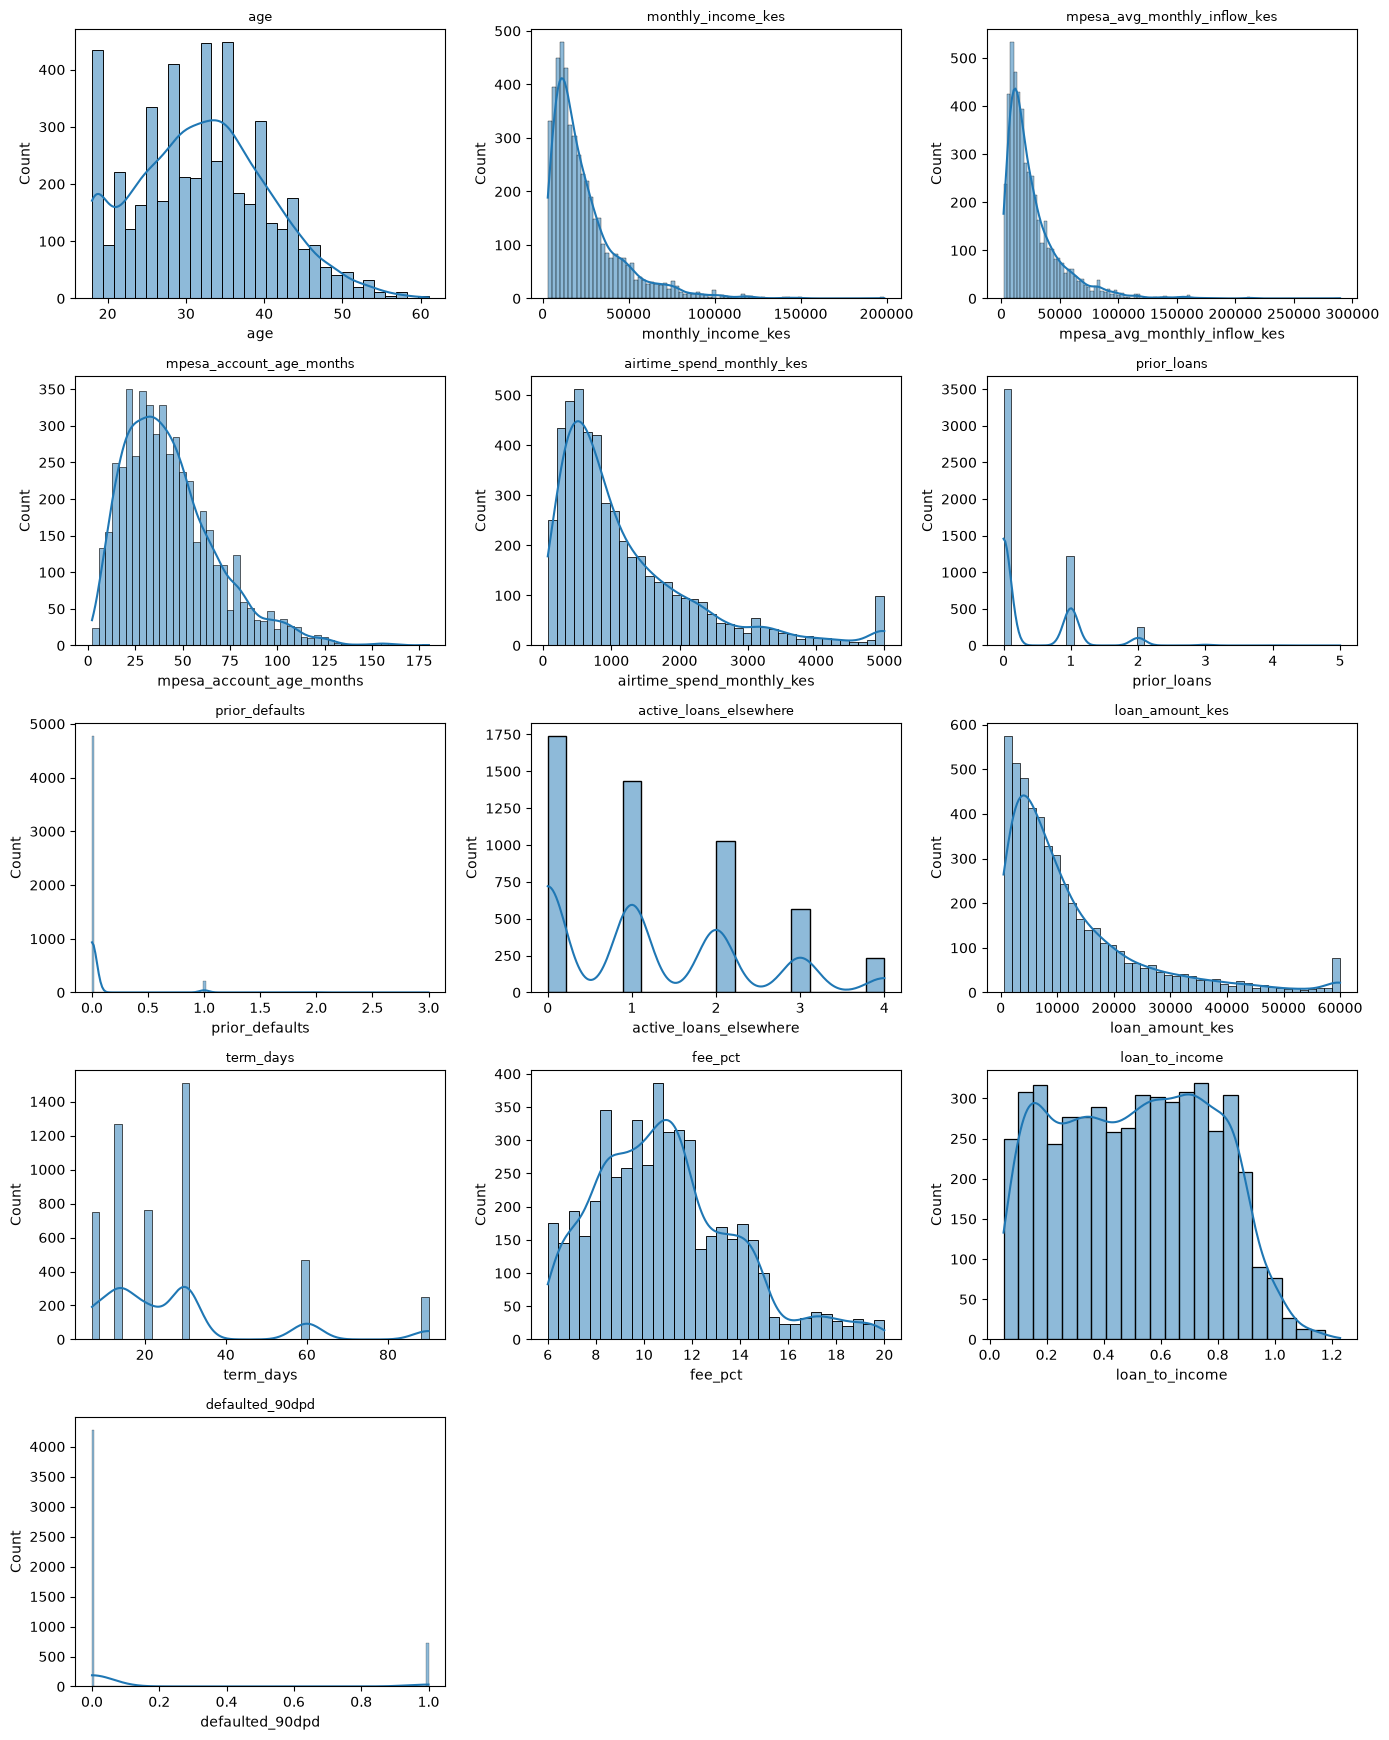

In [16]:
numeric_cols = df.select_dtypes(include="number").columns.drop("defaulted_90dpd").tolist()

n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = axes.flat

for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col, fontsize=9)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
df = df.copy()
df["mpesa_to_income"] = df["mpesa_avg_monthly_inflow_kes"] / df["monthly_income_kes"].clip(lower=1)
df["airtime_to_income"] = df["airtime_spend_monthly_kes"] / df["monthly_income_kes"].clip(lower=1)
df["loan_per_mpesa"] = df["loan_amount_kes"] / df["mpesa_avg_monthly_inflow_kes"].clip(lower=1)
df["has_prior_default"] = (df["prior_defaults"] > 0).astype(int)
df["total_prior_loans"] = df["prior_loans"] + df["active_loans_elsewhere"]

y = df["defaulted_90dpd"]
groups = df["borrower_id"]
X = df.drop(columns=["defaulted_90dpd", "loan_id", "borrower_id"])

cat_cols = ["county", "employment_type", "channel"]
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"numeric: {len(num_cols)}  categorical: {len(cat_cols)}")


numeric: 17  categorical: 3


In [18]:
pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), cat_cols),
])


In [19]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
tr_idx, te_idx = next(gss.split(X, y, groups=groups))

X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]
assert not set(groups.iloc[tr_idx]) & set(groups.iloc[te_idx])
print(f"train: {len(X_tr)}  test: {len(X_te)}  default rate tr/test: {y_tr.mean():.3f}/{y_te.mean():.3f}")


train: 4000  test: 1000  default rate tr/test: 0.147/0.139


In [20]:
rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=3,
    max_features="sqrt",
    class_weight="balanced_subsample",
    oob_score=True,
    n_jobs=-1,
    random_state=42,
)

pipe = Pipeline([("pre", pre), ("rf", rf)])
pipe.fit(X_tr, y_tr)
print(f"OOB score: {pipe.named_steps['rf'].oob_score_:.3f}")


OOB score: 0.846


In [21]:
y_prob = pipe.predict_proba(X_te)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_te, y_pred, digits=3))
print(f"ROC-AUC: {roc_auc_score(y_te, y_prob):.3f}")
print(f"PR-AUC : {average_precision_score(y_te, y_prob):.3f} (baseline = {y_te.mean():.3f})")
print(confusion_matrix(y_te, y_pred))


              precision    recall  f1-score   support

           0      0.875     0.958     0.915       861
           1      0.368     0.151     0.214       139

    accuracy                          0.846      1000
   macro avg      0.622     0.555     0.564      1000
weighted avg      0.804     0.846     0.817      1000

ROC-AUC: 0.730
PR-AUC : 0.303 (baseline = 0.139)
[[825  36]
 [118  21]]


In [22]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv = cross_validate(
    pipe,
    X,
    y,
    groups=groups,
    cv=sgkf,
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
    n_jobs=-1,
)
print("CV ROC-AUC: %.3f ± %.3f" % (cv["test_roc_auc"].mean(), cv["test_roc_auc"].std()))
print("CV PR-AUC : %.3f ± %.3f" % (cv["test_pr_auc"].mean(), cv["test_pr_auc"].std()))


CV ROC-AUC: 0.736 ± 0.027
CV PR-AUC : 0.338 ± 0.030


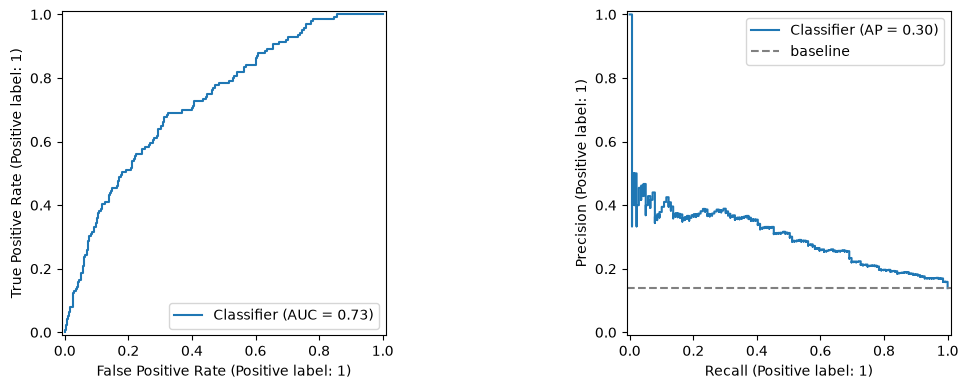

loan_to_income                  0.087439
active_loans_elsewhere          0.077115
loan_per_mpesa                  0.076720
total_prior_loans               0.071184
mpesa_to_income                 0.063472
monthly_income_kes              0.062811
fee_pct                         0.060948
airtime_to_income               0.060943
mpesa_avg_monthly_inflow_kes    0.060864
mpesa_account_age_months        0.059244
loan_amount_kes                 0.058043
airtime_spend_monthly_kes       0.057626
age                             0.049473
term_days                       0.026118
employment_type_Salaried        0.016392
dtype: float64


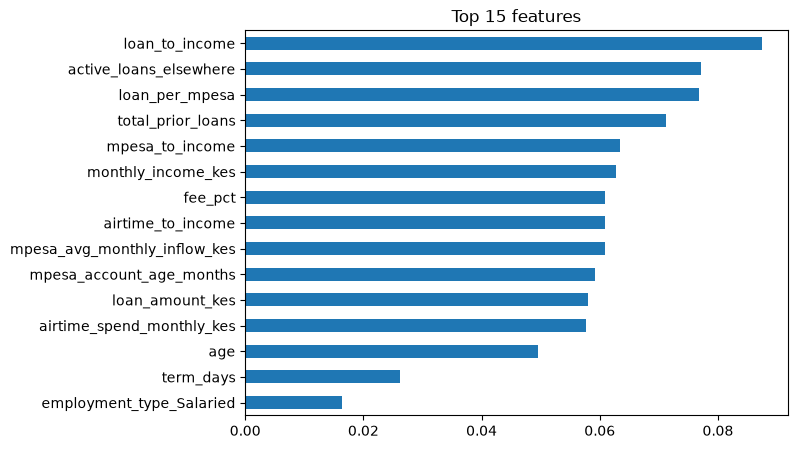

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_te, y_prob, ax=ax[0])
PrecisionRecallDisplay.from_predictions(y_te, y_prob, ax=ax[1])
ax[1].axhline(y_te.mean(), ls="--", c="grey", label="baseline")
ax[1].legend()
plt.tight_layout()
plt.show()

ohe = pipe.named_steps["pre"].named_transformers_["cat"]
feature_names = num_cols + list(ohe.get_feature_names_out(cat_cols))
importances = pd.Series(
    pipe.named_steps["rf"].feature_importances_, index=feature_names
).sort_values(ascending=False).head(15)
print(importances)
importances.sort_values().plot.barh(figsize=(7, 5))
plt.title("Top 15 features")
plt.show()


In [24]:
thresholds = np.linspace(0.05, 0.7, 66)
f1_scores = [f1_score(y_te, (y_prob >= threshold).astype(int)) for threshold in thresholds]
best_f1_threshold = thresholds[int(np.argmax(f1_scores))]
print(f"Best threshold by F1: {best_f1_threshold:.2f}")

amounts = X_te["loan_amount_kes"].to_numpy()
costs = []
for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)
    false_negatives = ((y_te == 1) & (predictions == 0)).to_numpy()
    false_positives = ((y_te == 0) & (predictions == 1)).to_numpy()
    costs.append(amounts[false_negatives].sum() + 0.1 * amounts[false_positives].sum())
best_cost_index = int(np.argmin(costs))
best_cost_threshold = thresholds[best_cost_index]
best_cost = costs[best_cost_index]
half_cost = costs[int(np.argmin(np.abs(thresholds - 0.5)))]
reduction = (1 - best_cost / half_cost) * 100 if half_cost else 0.0
print(f"Best threshold by cost: {best_cost_threshold:.2f}  "
      f"→ KES {best_cost:,.0f}  vs  KES {half_cost:,.0f} at 0.50  "
      f"({reduction:.1f}% reduction)")


Best threshold by F1: 0.32
Best threshold by cost: 0.19
